# Laboratorio de métodos de búsqueda

|                |   |
:----------------|---|
| **Nombre**     |  Alexa Bojorquez Valdivia |
| **Fecha**      |  22 de octubre  |
| **Expediente** |  745497 | 

Modelos como regresión logística, máquinas de vectores de soporte, y preceptrones multicapa tienen una serie de argumentos que necesitan valores dados antes de poder usarse para ajustarse a un dataset. Estos argumentos se llaman hiperparámetros.

¿Cuál es la diferencia entre un parámetro y un hiperparámetro?

- Los parámetros son los valores que el modelo aprende automáticamente al entrenarse con los datos, mientras que los hiperparámetros son los valores que nosotros definimos antes del entrenamiento, como el número de capas o neuronas.

Este laboratorio se centra en métodos de búsqueda para encontrar los mejores hiperparámetros para un modelo dado. Imagina que estás jugando batalla naval:

<center><img src="https://cdn11.bigcommerce.com/s-nehqfptb/images/stencil/670x993/products/40096/100569/battleship-game__73281.1768238533.jpg?c=2"></center>

Una forma de jugar podría ser ir de cuadro en cuadro hasta probar todo el tablero. El problema aquí es que se juega a contrarreloj, debido a que tu oponente puede hundir tus barcos antes de que pruebes todo el tablero.

Si no se tiene la preocupación/limitante de tiempo, probar todas las combinaciones es una opción:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

Entra a la documentación de `GridSearchCV` de `sklearn` y describe cómo funciona este objeto (entradas, salidas, parámetros).

- GridSearchCV busca los mejores hiperparámetros probando todas las combinaciones que le indicamos. Recibe un modelo, un conjunto de hiperparámetros (param_grid), una métrica (scoring) y el número de particiones (cv). Después de entrenarlo, podemos obtener la mejor combinación con best_params_, el mejor resultado con best_score_ y el modelo seleccionado con best_estimator_. Su desventaja es que puede tardar bastante cuando existen muchas combinaciones.

Otra forma de "buscar" podría ser tirar al azar y ver qué pasa. Esto sería otra forma de utilizar la fuerza bruta para encontrar información. 

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html

Entra a la documentación de `RandomizedSearchCV` de `sklearn` y describe cómo funciona este objeto (entradas, salidas, parámetros). 

- RandomizedSearchCV también busca los mejores hiperparámetros, pero en lugar de probar todas las combinaciones, selecciona algunas aleatoriamente. Recibe un modelo, los valores posibles (param_distributions), el número de combinaciones que queremos probar (n_iter), la métrica (scoring) y las particiones (cv). Al terminar, muestra los mejores hiperparámetros y su resultado. Puede ser más rápido que GridSearchCV, aunque no garantiza probar todas las combinaciones.

**Nota:** RandomizedSearchCV prueba puramente al azar. Si encontrara en uno de sus tiros que se atinó a un barco, no cambia el algoritmo de búsqueda para seguir buscando en esa zona. Para un proceso de búsqueda más refinado necesitaríamos un algoritmo que cambie su forma de decidir a partir de información anterior.

Revisa la documentación de Optuna (https://optuna.org/). Instala la librería y escribe una guía de cómo se debe utlizar para un dataset dado.

- Optuna es una librería que permite optimizar hiperparámetros utilizando los resultados de pruebas anteriores para decidir qué combinaciones probar después. Primero se define una función objectivo, donde se crea y evalúa el modelo. Después se utiliza trial.suggest_categorical() para seleccionar los hiperparámetros, create_study() para crear la búsqueda y study.optimize() para ejecutar las pruebas. Al finalizar, podemos consultar best_params y best_value.

### Ejercicio

Utiliza el dataset `College.csv` para intentar predecir si una universidad es privada a partir del resto de los factores.

Utiliza un perceptrón multicapa con hiperparámetros:
- Número de capas intermedias --> {2, 3, 4}
- Número de neuronas en capa 1 --> [5, 10]
- Número de neuronas en capa 2 --> [10, 20]
- Número de neuronas en capa 3 (si existe) --> [5, 20]
- Número de neuronas en capa 4 (si existe) --> [5, 10]

Utiliza k-folds cross-validation con $k=10$; optimiza el ROC-AUC de test.

Compara los 3 diferentes métodos de búsqueda descritos en este laboratorio.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

In [4]:
#Datos
data = pd.read_csv("College.csv")

print(data.shape)
print(data.dtypes)
print(data.isna().sum())

data.head()

(777, 19)
Unnamed: 0         str
Private            str
Apps             int64
Accept           int64
Enroll           int64
Top10perc        int64
Top25perc        int64
F.Undergrad      int64
P.Undergrad      int64
Outstate         int64
Room.Board       int64
Books            int64
Personal         int64
PhD              int64
Terminal         int64
S.F.Ratio      float64
perc.alumni      int64
Expend           int64
Grad.Rate        int64
dtype: object
Unnamed: 0     0
Private        0
Apps           0
Accept         0
Enroll         0
Top10perc      0
Top25perc      0
F.Undergrad    0
P.Undergrad    0
Outstate       0
Room.Board     0
Books          0
Personal       0
PhD            0
Terminal       0
S.F.Ratio      0
perc.alumni    0
Expend         0
Grad.Rate      0
dtype: int64


,Unnamed: 0,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
0,Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
1,Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
2,Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
3,Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
4,Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [ ]:
# Variable que queremos predecir
X = data.drop(columns=["Private"])
y = data["Private"].map({"Yes": 1, "No": 0})

# Eliminamos columnas de nombres si existen
X = X.drop(columns=["Unnamed: 0"], errors="ignore")

print(y.value_counts())
print(X.dtypes)

Private
1    565
0    212
Name: count, dtype: int64
Apps             int64
Accept           int64
Enroll           int64
Top10perc        int64
Top25perc        int64
F.Undergrad      int64
P.Undergrad      int64
Outstate         int64
Room.Board       int64
Books            int64
Personal         int64
PhD              int64
Terminal         int64
S.F.Ratio      float64
perc.alumni      int64
Expend           int64
Grad.Rate        int64
dtype: object


In [6]:
# Entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(621, 17)
(156, 17)


In [7]:
# Red neuronal y la validación cruzada
modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        max_iter=1000,
        random_state=42
    ))
])

kf = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

In [8]:
# 2, 3 y 4 capas
capas = []

for n1 in [5, 10]:
    for n2 in [10, 20]:

        capas.append((n1, n2))

        for n3 in [5, 20]:

            capas.append((n1, n2, n3))

            for n4 in [5, 10]:

                capas.append((n1, n2, n3, n4))

print("Número de combinaciones:", len(capas))

Número de combinaciones: 28


In [9]:
# GridSearchCV

parametros = {
    "mlp__hidden_layer_sizes": capas
}

inicio = time.time()

grid = GridSearchCV(
    modelo,
    param_grid=parametros,
    cv=kf,
    scoring="roc_auc",
    n_jobs=-1
)

grid.fit(X_train, y_train)

tiempo_grid = time.time() - inicio

print("Mejores capas:", grid.best_params_)
print("ROC-AUC CV:", grid.best_score_)
print("Tiempo:", tiempo_grid)

python(48181) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48182) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48183) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48184) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48185) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48186) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48187) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48188) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48189) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(48190) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
/opt/anaconda3/lib/p

Mejores capas: {'mlp__hidden_layer_sizes': (5, 10)}
ROC-AUC CV: 0.9803482878658709
Tiempo: 32.742350816726685


In [10]:
# Evaluamos el mejor modelo

prob_grid = grid.predict_proba(X_test)[:, 1]

auc_grid = roc_auc_score(y_test, prob_grid)

print("ROC-AUC test:", auc_grid)

ROC-AUC test: 0.9536941757563284


In [11]:
# RandomizedSearchCV

inicio = time.time()

random = RandomizedSearchCV(
    modelo,
    param_distributions=parametros,
    n_iter=15,
    cv=kf,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

random.fit(X_train, y_train)

tiempo_random = time.time() - inicio

print("Mejores capas:", random.best_params_)
print("ROC-AUC CV:", random.best_score_)
print("Tiempo:", tiempo_random)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_netwo

Mejores capas: {'mlp__hidden_layer_sizes': (5, 10)}
ROC-AUC CV: 0.9803482878658709
Tiempo: 20.500258922576904


In [12]:
# Evaluamos el mejor modelo

prob_random = random.predict_proba(X_test)[:, 1]

auc_random = roc_auc_score(y_test, prob_random)

print("ROC-AUC test:", auc_random)

ROC-AUC test: 0.9536941757563284


In [13]:
%pip install optuna

python(48193) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [optuna]2m3/4 [optuna]]
Note: you may need to restart the kernel to use updated packages.


In [14]:
import optuna

# Definimos la funcion

def objective(trial):

    arquitectura = trial.suggest_categorical(
        "arquitectura",
        list(range(len(capas)))
    )

    modelo_optuna = Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=capas[arquitectura],
            max_iter=1000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        modelo_optuna,
        X_train,
        y_train,
        cv=kf,
        scoring="roc_auc",
        n_jobs=-1
    )

    return scores.mean()

In [15]:
# Optuna

inicio = time.time()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=15)

tiempo_optuna = time.time() - inicio

mejores_capas = capas[study.best_params["arquitectura"]]

print("Mejores capas:", mejores_capas)
print("ROC-AUC CV:", study.best_value)
print("Tiempo:", tiempo_optuna)

[I 2026-10-29 17:18:44,761] A new study created in memory with name: no-name-8ca20d53-dcc8-46da-a275-2261c812ca70
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
[I 2026-10-29 17:18:49,924] Trial 0 finished with value: 0.9663368499573742 and parameters: {'arquitectura': 11}. Best is trial 0 with value: 0.9663368499573742.
[I 2026-10-29 17:18:51,271] Trial 1 finished with value: 0.9740164109121909 and parameters: {'arquitectura': 22}. Best is trial 1 with value: 0.9740164109121909.
[I 2026-10-29 17:18:53,200] Trial 2 finished with value: 0.9666545893719807 and parameters: {'arquitectura': 13}. Best is trial 1 with value: 0.9740164109121909.
[I 2026-10-29 17:18:54,392] Trial 3 finished with value: 0.9677960713270816 and parameters: {'arquitectura': 20}. Best is trial 1 with value: 0.9740164109121909.
[I 2

Mejores capas: (5, 20)
ROC-AUC CV: 0.9758928317703892
Tiempo: 26.677402019500732


In [16]:
# Evaluamos el mejor modelo

modelo_final_optuna = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=mejores_capas,
        max_iter=1000,
        random_state=42
    ))
])

modelo_final_optuna.fit(X_train, y_train)

prob_optuna = modelo_final_optuna.predict_proba(X_test)[:, 1]

auc_optuna = roc_auc_score(y_test, prob_optuna)

print("ROC-AUC test:", auc_optuna)

ROC-AUC test: 0.9555464087260754


In [17]:
# Comparamos los resultados de los tres métodos

resultados = pd.DataFrame({
    "Método": ["GridSearchCV", "RandomizedSearchCV", "Optuna"],
    "ROC-AUC CV": [
        grid.best_score_,
        random.best_score_,
        study.best_value
    ],
    "ROC-AUC test": [
        auc_grid,
        auc_random,
        auc_optuna
    ],
    "Tiempo (s)": [
        tiempo_grid,
        tiempo_random,
        tiempo_optuna
    ],
    "Combinaciones": [28, 15, 15]
})

resultados

,Método,ROC-AUC CV,ROC-AUC test,Tiempo (s),Combinaciones
0,GridSearchCV,0.980348,0.953694,32.742351,28
1,RandomizedSearchCV,0.980348,0.953694,20.500259,15
2,Optuna,0.975893,0.955546,26.677402,15


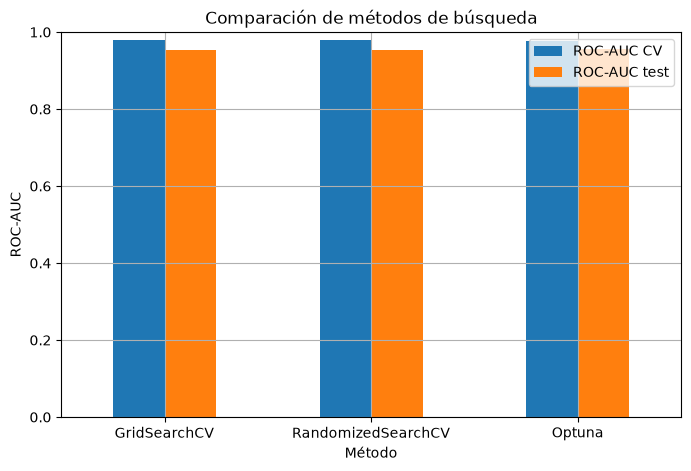

In [18]:
# Graficamos el ROC-AUC

resultados.plot(
    x="Método",
    y=["ROC-AUC CV", "ROC-AUC test"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Comparación de métodos de búsqueda")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(True)
plt.show()